# Laboratorio de Simulación Computacional, Práctica N.° 05
## ajuste de curvas y bondad de ajuste (sección 5.3)

Luciana Alejandra Belandria Agudelo (160005005)

Universidad de los Llanos, Ingeniería de Sistemas



In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

warnings.simplefilter("ignore")
pd.options.display.float_format = "{:,.6g}".format

ETIQUETAS = ["A", "B", "C", "D"]
PARTICIONES = 20
CARPETA_FIG = Path("graficas")
CARPETA_FIG.mkdir(exist_ok=True)

CANDIDATAS = [
    ("Exponencial", stats.expon, "positiva"),
    ("Lognormal", stats.lognorm, "positiva"),
    ("Normal", stats.norm, "libre"),
    ("Gamma", stats.gamma, "positiva"),
    ("Beta", stats.beta, "acotada"),
    ("Weibull", stats.weibull_min, "positiva"),
    ("Rayleigh", stats.rayleigh, "positiva"),
    ("Gaussiana inversa", stats.invgauss, "positiva"),
    ("Log-logística", stats.fisk, "positiva"),
]

In [2]:
pendientes = [f"dataset-{e}.txt" for e in ETIQUETAS if not Path(f"dataset-{e}.txt").exists()]
if pendientes:
    from google.colab import files
    print("Faltan:", pendientes)
    files.upload()

muestras = {e: np.loadtxt(f"dataset-{e}.txt") for e in ETIQUETAS}

def exportar(fig, nombre):
    fig.savefig(CARPETA_FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")

print({e: v.size for e, v in muestras.items()})

Faltan: ['dataset-A.txt', 'dataset-B.txt', 'dataset-C.txt', 'dataset-D.txt']


Saving dataset-A.txt to dataset-A.txt
Saving dataset-B.txt to dataset-B.txt
Saving dataset-C.txt to dataset-C.txt
Saving dataset-D.txt to dataset-D.txt
{'A': 200, 'B': 200, 'C': 200, 'D': 200}


## Ajuste de curvas y bondad de ajuste (guía, sección 5.3)

Se ajustan nueve modelos por máxima verosimilitud. En los modelos de soporte positivo el parámetro de localización queda fijo en cero; la beta se restringe al intervalo $[0,\,1.01\max x]$; la normal se ajusta sin restricciones. El número de parámetros libres $p$ entra en los criterios $\mathrm{AIC}=2p-2\ell$ y $\mathrm{BIC}=p\ln n-2\ell$, donde $\ell$ es la log-verosimilitud. El SSE suma los cuadrados de las diferencias entre la densidad empírica de 20 particiones y la densidad del modelo en el centro de cada partición.

In [3]:
def estimar(x, modelo, soporte):
    restricciones = {"positiva": {"floc": 0},
                     "acotada": {"floc": 0, "fscale": 1.01 * x.max()},
                     "libre": {}}[soporte]
    theta = modelo.fit(x, **restricciones)
    return theta, len(theta) - len(restricciones)

def describir_parametros(modelo, theta, soporte):
    nombres = (modelo.shapes.split(", ") if modelo.shapes else []) + ["loc", "scale"]
    ocultos = {"positiva": {"loc"}, "acotada": {"loc", "scale"}, "libre": set()}[soporte]
    return ", ".join(f"{a}={b:.4g}" for a, b in zip(nombres, theta) if a not in ocultos)

def evaluar_modelos(x):
    altura, bordes = np.histogram(x, bins=PARTICIONES, density=True)
    marcas = 0.5 * (bordes[1:] + bordes[:-1])
    registros = []
    for nombre, modelo, soporte in CANDIDATAS:
        theta, p = estimar(x, modelo, soporte)
        ell = np.sum(modelo.logpdf(x, *theta))
        registros.append({
            "Distribución": nombre,
            "Parámetros": describir_parametros(modelo, theta, soporte),
            "SSE": np.sum((modelo.pdf(marcas, *theta) - altura) ** 2),
            "AIC": 2 * p - 2 * ell,
            "BIC": p * np.log(x.size) - 2 * ell,
            "_modelo": modelo,
            "_theta": theta,
        })
    tabla = pd.DataFrame(registros)
    for criterio in ["SSE", "AIC", "BIC"]:
        tabla[f"Puesto {criterio}"] = tabla[criterio].rank(method="min").astype(int)
    return tabla

def superponer_mejores(e, tabla, cuantas=3):
    x = muestras[e]
    malla = np.linspace(x.min(), x.max(), 400)
    lienzo, eje = plt.subplots(figsize=(7, 4))
    eje.hist(x, bins=PARTICIONES, density=True, color="#aed6f1", edgecolor="white", label="Muestra")
    for _, fila in tabla.nsmallest(cuantas, "AIC").iterrows():
        eje.plot(malla, fila["_modelo"].pdf(malla, *fila["_theta"]), lw=2,
                 label=f'{fila["Distribución"]} (AIC = {fila["AIC"]:.1f})')
    eje.set(title=f"Dataset {e}: los tres modelos con menor AIC", xlabel="x", ylabel="Densidad")
    eje.legend()
    lienzo.tight_layout()
    exportar(lienzo, f"mejores_{e}")
    plt.show()


Bondad de ajuste, Dataset A


,Distribución,Parámetros,SSE,AIC,BIC,Puesto SSE,Puesto AIC,Puesto BIC
0,Exponencial,scale=0.195,340.471,-251.823,-248.524,9,9,9
1,Lognormal,"s=0.275, scale=0.189",36.9736,-611.089,-604.493,6,6,6
2,Normal,"loc=0.195, scale=0.0437",29.1478,-680.587,-673.99,2,1,1
3,Gamma,"a=16.18, scale=0.01206",28.2393,-647.342,-640.745,1,5,5
4,Beta,"a=5.902, b=3.234",29.3584,-675.736,-669.14,3,3,3
5,Weibull,"c=5.071, scale=0.212",32.4271,-679.356,-672.76,4,2,2
6,Rayleigh,scale=0.1413,185.201,-496.998,-493.7,8,8,8
7,Gaussiana inversa,"mu=0.08962, scale=2.176",48.0592,-583.422,-576.825,7,7,7
8,Log-logística,"c=7.293, scale=0.1927",33.4179,-655.443,-648.846,5,4,4


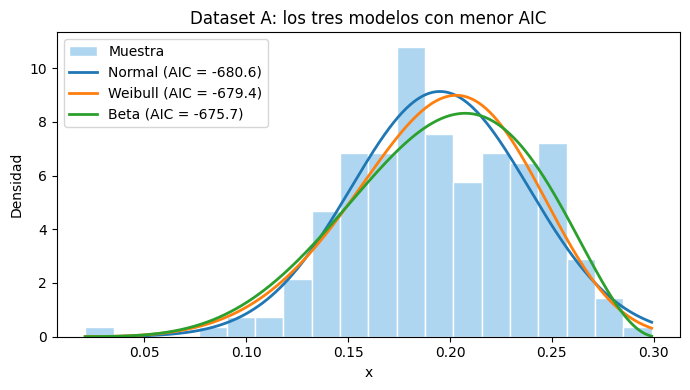


Bondad de ajuste, Dataset B


,Distribución,Parámetros,SSE,AIC,BIC,Puesto SSE,Puesto AIC,Puesto BIC
0,Exponencial,scale=0.2054,0.435755,-231.131,-227.833,3,3,1
1,Lognormal,"s=1.437, scale=0.104",2.32601,-188.735,-182.138,6,6,6
2,Normal,"loc=0.2054, scale=0.2285",11.5696,-18.889,-12.2924,8,7,7
3,Gamma,"a=0.8636, scale=0.2378",0.315773,-232.098,-225.501,2,2,3
4,Beta,"a=0.6894, b=4.115",1.11063,-207.307,-200.71,4,4,4
5,Weibull,"c=0.9095, scale=0.1963",0.276188,-232.264,-225.667,1,1,2
6,Rayleigh,scale=0.2173,18.1248,85.9907,89.289,9,8,8
7,Gaussiana inversa,"mu=22.4, scale=0.009169",6.52825,151.986,158.583,7,9,9
8,Log-logística,"c=1.307, scale=0.1184",1.14324,-206.652,-200.056,5,5,5


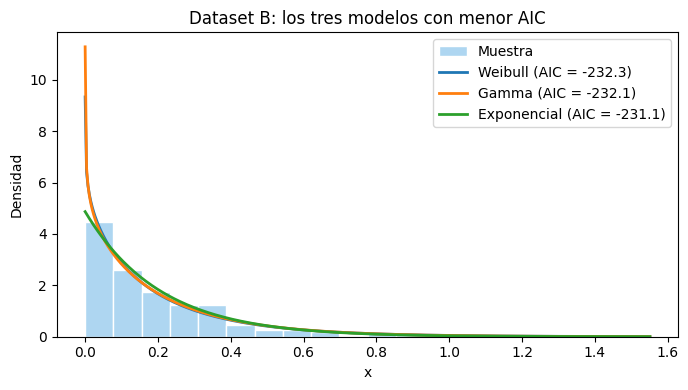


Bondad de ajuste, Dataset C


,Distribución,Parámetros,SSE,AIC,BIC,Puesto SSE,Puesto AIC,Puesto BIC
0,Exponencial,scale=762.4,5.97832e-08,"3,056.59","3,059.88",4,3,3
1,Lognormal,"s=1.648, scale=324.3",6.36106e-08,"3,084.19","3,090.78",5,6,6
2,Normal,"loc=762.4, scale=920.8",9.26457e-07,"3,301.68","3,308.28",8,7,7
3,Gamma,"a=0.7062, scale=1080",4.49321e-08,"3,040.22","3,046.82",3,1,1
4,Beta,"a=0.5847, b=4.109",1.2982e-07,"3,061.97","3,068.57",6,4,4
5,Weibull,"c=0.8007, scale=676",2.5238e-08,"3,040.81","3,047.41",1,2,2
6,Rayleigh,scale=845.3,1.43385e-06,"3,481.09","3,484.39",9,9,9
7,Gaussiana inversa,"mu=19.81, scale=38.49",3.2243e-07,"3,310.51","3,317.11",7,8,8
8,Log-logística,"c=1.126, scale=384.4",4.07555e-08,"3,072.48","3,079.08",2,5,5


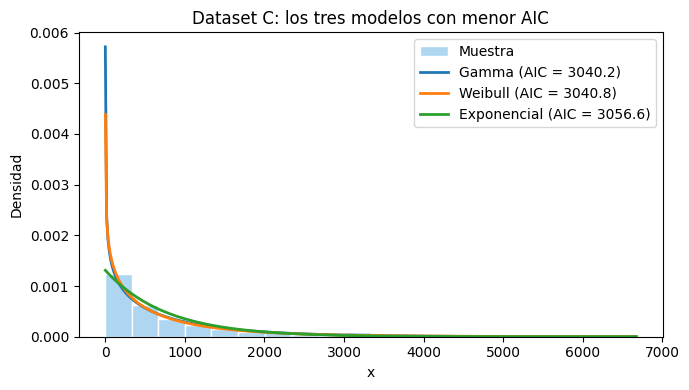


Bondad de ajuste, Dataset D


,Distribución,Parámetros,SSE,AIC,BIC,Puesto SSE,Puesto AIC,Puesto BIC
0,Exponencial,scale=2.06,0.00989812,691.179,694.477,3,5,4
1,Lognormal,"s=1.019, scale=1.273",0.00691347,675.893,682.489,2,1,1
2,Normal,"loc=2.06, scale=2.321",0.117489,908.333,914.93,8,8,8
3,Gamma,"a=1.178, scale=1.749",0.0104769,689.967,696.564,4,4,5
4,Beta,"a=0.8645, b=5.872",0.0248991,739.021,745.618,6,7,7
5,Weibull,"c=1.042, scale=2.099",0.0106563,692.547,699.144,5,6,6
6,Rayleigh,scale=2.194,0.15718,934.062,937.361,9,9,9
7,Gaussiana inversa,"mu=1.763, scale=1.169",0.0254869,685.398,691.995,7,3,3
8,Log-logística,"c=1.705, scale=1.31",0.00601113,681.403,687.999,1,2,2


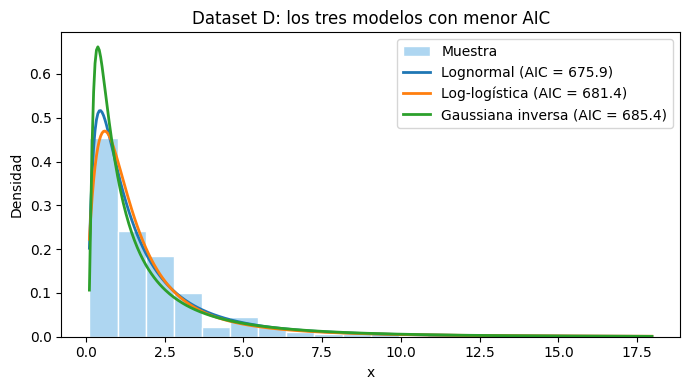

In [4]:
resultados = {}
for e in ETIQUETAS:
    resultados[e] = evaluar_modelos(muestras[e])
    print(f"\nBondad de ajuste, Dataset {e}")
    display(resultados[e].drop(columns=["_modelo", "_theta"]))
    superponer_mejores(e, resultados[e])

## Síntesis

In [5]:
sintesis = pd.DataFrame({
    e: {**{f"Puesto {i} (AIC)": nombre for i, nombre in enumerate(resultados[e].nsmallest(3, "AIC")["Distribución"], start=1)},
        "Menor BIC": resultados[e].nsmallest(1, "BIC")["Distribución"].iloc[0],
        "Menor SSE": resultados[e].nsmallest(1, "SSE")["Distribución"].iloc[0]}
    for e in ETIQUETAS
}).T
display(sintesis)

,Puesto 1 (AIC),Puesto 2 (AIC),Puesto 3 (AIC),Menor BIC,Menor SSE
A,Normal,Weibull,Beta,Normal,Gamma
B,Weibull,Gamma,Exponencial,Exponencial,Weibull
C,Gamma,Weibull,Exponencial,Gamma,Weibull
D,Lognormal,Log-logística,Gaussiana inversa,Lognormal,Log-logística


### Las tres mejores distribuciones de cada conjunto, con sus parámetros

In [6]:
for e in ETIQUETAS:
    print(f"\nDataset {e}")
    display(resultados[e].nsmallest(3, "AIC")[["Distribución", "Parámetros", "SSE", "AIC", "BIC"]].reset_index(drop=True))


Dataset A


,Distribución,Parámetros,SSE,AIC,BIC
0,Normal,"loc=0.195, scale=0.0437",29.1478,-680.587,-673.99
1,Weibull,"c=5.071, scale=0.212",32.4271,-679.356,-672.76
2,Beta,"a=5.902, b=3.234",29.3584,-675.736,-669.14



Dataset B


,Distribución,Parámetros,SSE,AIC,BIC
0,Weibull,"c=0.9095, scale=0.1963",0.276188,-232.264,-225.667
1,Gamma,"a=0.8636, scale=0.2378",0.315773,-232.098,-225.501
2,Exponencial,scale=0.2054,0.435755,-231.131,-227.833



Dataset C


,Distribución,Parámetros,SSE,AIC,BIC
0,Gamma,"a=0.7062, scale=1080",4.49321e-08,"3,040.22","3,046.82"
1,Weibull,"c=0.8007, scale=676",2.5238e-08,"3,040.81","3,047.41"
2,Exponencial,scale=762.4,5.97832e-08,"3,056.59","3,059.88"



Dataset D


,Distribución,Parámetros,SSE,AIC,BIC
0,Lognormal,"s=1.019, scale=1.273",0.00691347,675.893,682.489
1,Log-logística,"c=1.705, scale=1.31",0.00601113,681.403,687.999
2,Gaussiana inversa,"mu=1.763, scale=1.169",0.0254869,685.398,691.995
